# End-to-End Adaptive Optics with **Soapy** — Lab Part 2 (short, ~2 h)

**AO school lab — Part 2 of 2.** Part 1 (`aotools_lab_part1_short.ipynb`) built the ingredients — PSFs, Zernikes, $r_0$ ↔ seeing ↔ $C_n^2$, phase screens, imaging through turbulence. Here we assemble them into a **full end-to-end AO loop** with [`soapy`](https://github.com/AOtools/soapy) (configs in `conf/`, source in `soapy` repo): configure an 8 m Shack–Hartmann SCAO system, calibrate it, close the loop.

### Objectives
1. soapy architecture: one YAML config → one `Sim`; `aoinit()` / `makeIMat()` / `aoloop()`.
2. Read/modify a config on disk and in Python.
3. Open loop: slopes, spot pattern, seeing-limited PSF, WFE.
4. Calibration: pokes → `D`, `R = pinv(D)` (SVD-conditioned).
5. Closed loop: gain/delay/$r_0$ sweeps; error budgets (fitting, aliasing, temporal).
6. Extras: pyramid WFS (`conf/pwfs.yaml`), modal DM (`Zernike`/`KarhunenLoeve`).

### Session plan (~2 h)

| # | Section | Time |
|---|---------|------|
| 0 | Setup: `soapy` tour, configs | 5 min |
| 1 | Working principle: `Sim`, config, `aoinit` / `loopFrame` | 15 min |
| 2 | Open loop: slopes, PSF, WFE | 15 min |
| 3 | Calibration: iMat, SVD, cMat, poke video | 20 min |
| 4 | Closed loop: gain/delay, loop video | 20 min |
| 5 | Exercises & summary: error budgets, fiber, PWFS, modal DM | 30 min |

### Conventions
- Run from the repo root; configs in `conf/`. `simName = None` → no FITS on disk; `randomSeed` → reproducible atmosphere. Units: nm OPD @ 500 nm, subap px (slopes), arcsec (FOV/EE50); $r_0$ at 500 nm.
- Reference config `sh_8x8.yaml`: 8 m tel. (1.1 m obscuration), 4 frozen-flow layers ($r_0=0.16$ m, $L_0=20$ m), on-axis 8×8 SH WFS @ 600 nm, TT + 9×9 DM, MVM, sci cam @ 1.65 µm. SCAO throughout — LGS/MCAO only in the summary pointers.


## 0. Setup — the `soapy` toolbox
For an introduction of the architecture, check here: https://soapy.readthedocs.io/en/latest/architecture.html

`soapy` is a **config-driven, end-to-end AO simulator**: one YAML → one `Sim`; WFSs, DMs, reconstructors are interchangeable blocks:

| Module | Classes |
|---|---|
| `soapy` (+ `confParse`, `lineofsight`) | `Sim`, `loadSoapyConfig`, `make_mask`, `YAML_Configurator`, `LineOfSight` |
| `soapy.atmosphere` | `atmos`, `moveScrns()`, frozen-flow infinite screens |
| `soapy.wfs` | `ShackHartmann`, `Pyramid`, `Gradient`, `Zernike`, `ExtendedSH` |
| `soapy.DM` | `TT`, `Piezo`, `FastPiezo`, `GaussStack`, `Zernike`, `KarhunenLoeve`, `CustomShapes` |
| `soapy.reconstruction` | `MVM`, `MVM_SeparateDMs`, `LearnAndApply`, `WooferTweeter`, `ANN` |
| `soapy.scienceinstrument` | `PSFCamera`, `singleModeFibre` |

Here: configs in `conf/`; more configs + tests in `assets/soapy/`; component notebooks in `assets/soapytest/`; OOPAO in `assets/ORP_AO_School_How_To.ipynb`. Install: `pip install -r requirements.txt`. Docs: http://soapy.readthedocs.io; CLI: `soapy conf/sh_8x8.yaml`.


In [1]:
# ============================================================
# Setup — run this cell first
# ============================================================
%matplotlib inline

import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import soapy     # end-to-end AO simulator (assets/soapy)
import aotools   # reused from Part 1 (r0 <-> seeing conversions)

print('soapy   :', soapy.__version__)
print('aotools :', aotools.__version__)
print('numpy   :', np.__version__)

plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['image.origin'] = 'lower'
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['figure.max_open_warning'] = 0   # this notebook opens many figures

def logim(im, floor=1e-12):
    # log10 of an image, floored so the far PSF wings don't give log10(0) warnings
    return np.log10(np.maximum(im, floor))

def soapy_conf(name):
    # Locate a config file in this repo's conf/ directory, searching upwards from the cwd
    candidates = [os.path.join('conf', name)]
    d = os.getcwd()
    for _ in range(4):
        candidates.append(os.path.join(d, 'conf', name))
        d = os.path.dirname(d)
    for c in candidates:
        if os.path.exists(c):
            print('config found:', c)
            return c
    raise FileNotFoundError(name + ' not found in conf/ — run from the ao_school repo')

def crop_to_pupil(a, sim):
    # Central simSize x simSize slice of a (larger) scrnSize screen — the part matching sim.mask.
    s = sim.config.sim.simSize
    c = a.shape[0] // 2
    return a[c - s//2 : c + s//2, c - s//2 : c + s//2]

def subap_centres(sim, wfs):
    # Centres of the active sub-apertures in the sim-array frame, as (col, row) — ready for
    # scatter/quiver (imshow: horizontal = col, vertical = row). soapy stores sub-aperture
    # CORNERS in the pupil array (wfs.pupil_subap_coords), so add half a sub-aperture and
    # then the simPad offset to reach the sim.mask frame.
    pad = sim.config.sim.simPad
    sp = sim.config.sim.pupilSize / wfs.nx_subaps          # px per subap across the pupil
    c = wfs.pupil_subap_coords.astype(float) + 0.5 * sp    # corners -> centres
    return c[:, 1] + pad, c[:, 0] + pad                    # (col, row)


soapy   : 0.14.0+7.g36588ed
aotools : 0.1.dev477+g8f38ff7c1.d20260605
numpy   : 2.4.2


---
# Section 1 — The working principle of soapy (~15 min)

One YAML config → one `Sim`. Each `loopFrame()`: `moveScrns()` → WFS measures residual slopes → `commands = cMat^T . slopes` → DM commands (delayed `loopDelay` frames) → DM shape → science camera. Closed loop: the DM shape is subtracted from the next frame's turbulence.

Workflow (also what the CLI does):

    sim = soapy.Sim("conf/sh_8x8.yaml")   # 1. read config
    sim.aoinit()                           # 2. build all objects
    sim.makeIMat()                         # 3. calibration: D -> R
    sim.aoloop()                           # 4. run nIters frames

Run data lives on the `sim` object:

| Data | Attribute |
|---|---|
| pupil mask / screens [nm @500 nm] | `sim.mask` / `sim.atmos.scrns`, `sim.scrns` |
| slopes [subap px] / spot pattern | `sim.slopes`, `sim.allSlopes` / `sim.wfss[0].wfsDetectorPlane` |
| DM commands / shapes | `sim.dmCommands`, `sim.allDmCommands`, `sim.combinedCorrection` |
| sci PSF (long/inst), residual phase [nm] | `sim.sciImgs[0]`, `sim.sciImgsInst[0]`, `sim.sciPhase[0]` |
| Strehl inst/long, WFE [nm], EE50 [arcsec] | `sim.instStrehl[0]`, `sim.longStrehl[0]`, `sim.WFE[0]`, `sim.ee50d[0]` |
| calibration matrices | `sim.recon.interaction_matrix`, `sim.recon.control_matrix` |


### 1.1 Anatomy of a YAML config

One config, split into sections; anything can be overridden in Python after loading (as `assets/soapy/test/` does):

| Section | Key parameters |
|---|---|
| top level | `pupilSize`, `nGS/nDM/nSci`, `nIters`, `loopTime`, `loopDelay`, `simName`, `save*` |
| `Atmosphere` | heights/strengths/winds, `r0`, `L0`, `wholeScrnSize`, `infinite`, `randomSeed` |
| `Telescope` | `telDiam`, `obsDiam`, `mask` |
| `WFS` | `type`, `GSPosition`, `nxSubaps`, `pxlsPerSubap`, `subapFOV`, `wavelength` |
| `DM` / `Reconstructor` | `type`, `closed`, `nxActuators`, `iMatValue`, `gain` / `svdConditioning` |
| `Science` | `position`, `FOV` [arcsec], `wavelength`, `pxls` |


In [2]:
# --- 1.1 Load a config file and inspect the parsed parameters -------------
conf_file = soapy_conf('sh_8x8.yaml')

config = soapy.loadSoapyConfig(conf_file)

print('--- sim (top level) ---')
for p in ['pupilSize', 'nGS', 'nDM', 'nSci', 'nIters', 'loopTime', 'loopDelay', 'simName', 'verbosity']:
    print(f'  {p:12s} = {getattr(config.sim, p, "<default>")}')

print('--- Atmosphere ---')
for p in ['scrnNo', 'scrnHeights', 'scrnStrengths', 'windDirs', 'windSpeeds', 'r0', 'L0', 'infinite', 'randomSeed']:
    print(f'  {p:15s} = {getattr(config.atmos, p, "<default>")}')

print('--- Telescope ---')
print(f'  telDiam = {config.tel.telDiam} m, obsDiam = {config.tel.obsDiam} m, mask = {config.tel.mask}')

w = config.wfss[0]
print('--- WFS 0 ---')
print(f'  type = {w.type}, GSPosition = {w.GSPosition}, GSHeight = {w.GSHeight}, GSMag = {w.GSMag}')
print(f'  nxSubaps = {w.nxSubaps}, pxlsPerSubap = {w.pxlsPerSubap}, subapFOV = {w.subapFOV} arcsec, '
      f'wavelength = {w.wavelength*1e9:.0f} nm, propagationMode = {w.propagationMode}')

print('--- DMs ---')
for d, dm in enumerate(config.dms):
    print(f'  DM {d}: type = {dm.type}, closed = {dm.closed}, nxActuators = {dm.nxActuators}, '
          f'iMatValue = {dm.iMatValue}, gain = {dm.gain}')

print('--- Reconstructor / Science ---')
print(f'  recon: type = {config.recon.type}, svdConditioning = {config.recon.svdConditioning}, gain = {config.recon.gain}')
s = config.scis[0]
print(f'  sci 0: position = {s.position}, FOV = {s.FOV} arcsec, wavelength = {s.wavelength*1e6:.2f} um, pxls = {s.pxls}')


config found: conf/sh_8x8.yaml
--- sim (top level) ---
  pupilSize    = 100
  nGS          = 1
  nDM          = 2
  nSci         = 1
  nIters       = 5000
  loopTime     = 0.0025
  loopDelay    = 0
  simName      = None
  verbosity    = 2
--- Atmosphere ---
  scrnNo          = 4
  scrnHeights     = [    0  5000 10000 15000]
  scrnStrengths   = [0.5 0.3 0.1 0.1]
  windDirs        = [  0  45  90 135]
  windSpeeds      = [10 10 15 20]
  r0              = 0.16
  L0              = [20 20 20 20]
  infinite        = True
  randomSeed      = None
--- Telescope ---
  telDiam = 8.0 m, obsDiam = 1.1 m, mask = circle
--- WFS 0 ---
  type = ShackHartmann, GSPosition = [0 0], GSHeight = 0, GSMag = 8
  nxSubaps = 8, pxlsPerSubap = 10, subapFOV = 2.5 arcsec, wavelength = 600 nm, propagationMode = Geometric
--- DMs ---
  DM 0: type = TT, closed = True, nxActuators = None, iMatValue = 0.25, gain = 0.6
  DM 1: type = FastPiezo, closed = True, nxActuators = 9, iMatValue = 500.0, gain = 0.6
--- Reconstruct

In [3]:
# --- 1.1b The same config, edited in Python before aoinit() ---------------
# (this is exactly what the soapy tests in assets/soapy/test/ do)
sim = soapy.Sim(conf_file)

# Keep the run light, reproducible, and silent on disk:
sim.config.sim.simName  = None    # no FITS output directory
sim.config.sim.logfile  = None
sim.config.sim.verbosity = 1
sim.config.sim.nIters   = 300     # loop frames (5000 in the shipped file)
sim.config.atmos.randomSeed = 0   # reproducible atmosphere

# Turn on the data streams we want to analyse afterwards
sim.config.sim.saveSlopes     = True
sim.config.sim.saveDmCommands = True
sim.config.sim.saveInstPsf    = True
sim.config.sim.saveSciRes     = True

print('overridden: nIters =', sim.config.sim.nIters, '| randomSeed =', sim.config.atmos.randomSeed)

# The raw YAML of the reference config (first lines)
with open(conf_file) as f:
    txt = f.read()
print()
print('--- raw YAML, first 40 lines of', conf_file.split('/')[-1], '---')
print('\n'.join(txt.splitlines()[:100]))


overridden: nIters = 300 | randomSeed = 0

--- raw YAML, first 40 lines of sh_8x8.yaml ---
simName:
pupilSize: 100
nGS: 1
nDM: 2
nSci: 1
nIters: 5000
loopTime: 0.0025
threads: 4

verbosity: 2

saveCMat: False
saveSlopes: True
saveDmCommands:   False
saveLgsPsf: False
saveSciPsf: True


Atmosphere:
  scrnNo: 4
  scrnHeights: [0, 5000, 10000, 15000]
  scrnStrengths: [0.5, 0.3, 0.1, 0.1]
  windDirs: [0, 45, 90, 135]
  windSpeeds: [10, 10, 15, 20]
  wholeScrnSize: 2048
  r0: 0.16
  L0: [20, 20, 20, 20]
  infinite: True


Telescope:
  telDiam: 8.
  obsDiam: 1.1
  mask: circle

WFS:
  0:
    type: ShackHartmann
    GSPosition: [0, 0]
    GSHeight: 0
    GSMag: 8
    nxSubaps: 8
    pxlsPerSubap: 10
    subapFOV: 2.5
    wavelength: 600e-9

DM:
  0:
    type: TT
    closed: True
    iMatValue: 0.25


  1:
    type: FastPiezo
    closed: True
    nxActuators: 9
    iMatValue: 500

Reconstructor:
  type: MVM
  svdConditioning: 0.03
  gain: 0.6

Science:
  0:
    position: [0, 0]
    FOV: 1.0
  

### 1.2 `aoinit()` — building the AO system

`aoinit()` instantiates everything from the config: pupil mask (`sim.mask`), atmosphere (`sim.atmos`, frozen-flow layers extruded with `infinite: True`), WFSs (`sim.wfss`), DMs (`sim.dms`), reconstructor (`sim.recon`), science cameras (`sim.sciCams`).


In [4]:
# --- 1.2 aoinit: build the system, then take inventory --------------------
sim.aoinit()

print(f'pupil mask : sim.mask {sim.mask.shape}, {int(sim.mask.sum())} illuminated px, '
      f'simSize = {sim.config.sim.simSize}, scrnSize = {sim.config.sim.scrnSize}')
print(f'pixel scale: {sim.config.sim.pxlScale:.2f} px/m = {1/sim.config.sim.pxlScale*100:.1f} cm/px')
print(f'atmosphere : {sim.atmos.scrnNo} layers, r0 = {sim.atmos.r0} m @ 500 nm, '
      f'screens {sim.atmos.scrn_size}x{sim.atmos.scrn_size}, infinite = {sim.config.atmos.infinite}')
for n, wfs in sim.wfss.items():
    print(f'WFS {n}      : {type(wfs).__name__}, {wfs.n_subaps} active subaps on a {wfs.nx_subaps}x{wfs.nx_subaps} grid '
          f'-> {wfs.n_measurements} measurements, subap diam = {wfs.subap_diam:.2f} m, '
          f'wfs px scale = {wfs.pixel_scale:.3f} arcsec/px')
for d, dm in sim.dms.items():
    print(f'DM {d}      : {type(dm).__name__}, {dm.n_acts} actuators, closed = {dm.dmConfig.closed}')
print(f'recon      : {type(sim.recon).__name__}')
for n, sci in sim.sciCams.items():
    print(f'sci cam {n} : {type(sci).__name__}, {sci.nx_pixels}x{sci.nx_pixels} px, FOV = {sci.fov} arcsec')


pupil mask : sim.mask (102, 102), 7712 illuminated px, simSize = 102, scrnSize = 102
pixel scale: 12.50 px/m = 8.0 cm/px
atmosphere : 4 layers, r0 = 0.16 m @ 500 nm, screens 102x102, infinite = True
WFS 0      : ShackHartmann, 52 active subaps on a 8x8 grid -> 104 measurements, subap diam = 1.00 m, wfs px scale = 0.250 arcsec/px
DM 0      : TT, 2 actuators, closed = True
DM 1      : FastPiezo, 81 actuators, closed = True
recon      : MVM
sci cam 0 : PSFCamera, 64x64 px, FOV = 1.0 arcsec


phase screens: (4, 102, 102) -> nm OPD referred to 500 nm
layer 0 rms over the screen: 589.1 nm


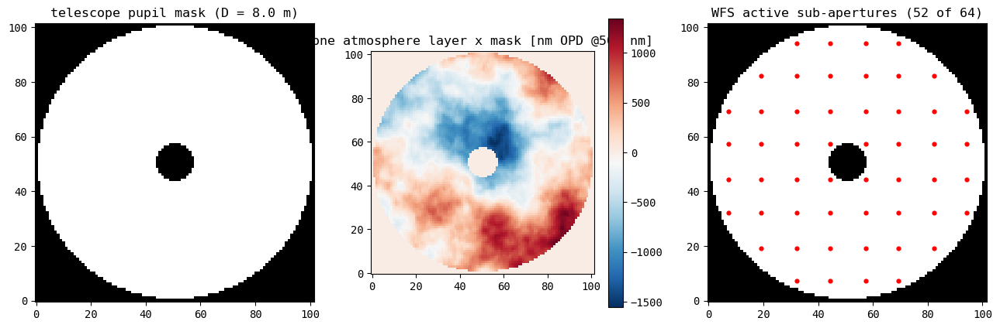

In [5]:
# --- 1.2b First look at the built system: pupil, one layer, WFS geometry ---
scrns = sim.atmos.moveScrns()   # one frozen-flow step; units: nm OPD at 500 nm
print('phase screens:', scrns.shape, '-> nm OPD referred to 500 nm')
print(f'layer 0 rms over the screen: {scrns[0].std():.1f} nm')

wfs = sim.wfss[0]
cx, cy = subap_centres(sim, wfs)   # sub-aperture centres in the sim-array frame: (col, row)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
ax[0].imshow(sim.mask, cmap='gray')
ax[0].set_title(f'telescope pupil mask (D = {sim.config.tel.telDiam} m)')
im = ax[1].imshow(crop_to_pupil(scrns[0], sim) * sim.mask, cmap='RdBu_r')
ax[1].set_title('one atmosphere layer x mask [nm OPD @500 nm]'); fig.colorbar(im, ax=ax[1])
ax[2].imshow(sim.mask, cmap='gray')
ax[2].scatter(cx, cy, c='r', s=12)   # imshow: horizontal = col, vertical = row
ax[2].set_title(f'WFS active sub-apertures ({wfs.n_subaps} of {wfs.nx_subaps**2})')
plt.tight_layout()


### 1.3 Stepping the loop by hand — `loopFrame()`

`aoloop()` = `loopFrame()` × `nIters`; one frame: `moveScrns()` → `recon.reconstruct(slopes)` → delay `loopDelay` → `runDM(commands)` → `runWfs(dmShape=correction)` (WFS sees the **residual**) → `runSciCams()` → `storeData(i)`.

> `loopFrame()` / `reset_loop()` need `makeIMat()` first — pre-calibration we step the pieces by hand (below).


In [6]:
# --- 1.3 Stepping a frame by hand (before calibration) ---------------------
# loopFrame()/reset_loop() need makeIMat() first (runDM uses dm.n_valid_actuators,
# DM.reset() uses dm.dm_shape) — so pre-calibration we step the pieces manually:
# moveScrns -> runWfs -> runSciCams. (No reset needed: aoinit zeroed the buffers.)
for i in range(3):
    sim.scrns = sim.atmos.moveScrns()                      # advance the frozen flow
    sim.slopes = sim.runWfs(scrns=sim.scrns, loopIter=i)   # WFS sees the full turbulence (no DM shape)
    sim.runSciCams(dmShape=None)                           # science camera, open loop
    print(f'frame {i}: slopes[:4] = {np.round(sim.slopes[:4], 3)} px, '
          f'inst Strehl = {sim.sciCams[0].instStrehl:.3f}, '
          f'WFE = {sim.sciCams[0].calc_wavefronterror():.0f} nm')
print('WFS data per frame:', sim.config.sim.totalWfsData, '= 2 x', sim.wfss[0].n_subaps, 'subaps')
print('slope layout    : slopes[:n_subaps] = x-slopes, slopes[n_subaps:] = y-slopes [subap px]')
print('screen units    : sim.scrns in nm OPD @500 nm, layer-0 rms =', round(float(sim.scrns[0].std()), 1), 'nm')


frame 0: slopes[:4] = [ 0.151 -0.243 -0.69   0.334] px, inst Strehl = 0.073, WFE = 612 nm
frame 1: slopes[:4] = [ 0.186 -0.245 -0.727  0.344] px, inst Strehl = 0.073, WFE = 608 nm
frame 2: slopes[:4] = [ 0.22  -0.244 -0.738  0.337] px, inst Strehl = 0.074, WFE = 602 nm
WFS data per frame: 104 = 2 x 52 subaps
slope layout    : slopes[:n_subaps] = x-slopes, slopes[n_subaps:] = y-slopes [subap px]
screen units    : sim.scrns in nm OPD @500 nm, layer-0 rms = 589.1 nm


### Exercise 1 — configuration & initialisation
1. `obsDiam = 0` then re-`aoinit()`: active sub-apertures left? `nxSubaps` 8 → 16?
2. Per frame (`loopTime = 2.5 ms`), how far does each layer move vs `subap_diam`?
3. soapy's `tau0 = 0.314 r0 / vBar^(5/3)` vs `aotools.coherenceTime` (Part 1)?


---
# Section 2 — Open loop (~15 min)

Open loop (`sh_8x8_openloop.yaml`: `closed: False`, gain 0): WFS measures the **full turbulence**, camera the **seeing-limited PSF** (core+halo, Part 1 §5). `makeIMat()` still first, then `aoloop()`. Streams: `allSlopes`, `sciPhase[0]`, `sciImgsInst[0]`/`sciImgs[0]`, `instStrehl`/`longStrehl`, `WFE`, `ee50d`.


In [7]:
# --- 2.1 Open-loop run of the reference system ----------------------------
open_sim = soapy.Sim(soapy_conf('sh_8x8_openloop.yaml'))
open_sim.config.sim.simName  = None
open_sim.config.sim.logfile  = None
open_sim.config.sim.verbosity = 0
open_sim.config.sim.nIters   = 300
open_sim.config.atmos.randomSeed = 0
for f in ['saveSlopes', 'saveDmCommands', 'saveInstPsf', 'saveSciRes']:
    setattr(open_sim.config.sim, f, True)

open_sim.aoinit()
open_sim.makeIMat(forceNew=True)   # required before any loop frame: runDM needs dm.n_valid_actuators
for dm in open_sim.config.dms:
    dm.gain = 0.0                  # gain 0 -> DMs apply nothing: pure open loop
open_sim.aoloop()

n_open = open_sim.config.sim.nIters
print('open-loop results over', n_open, 'frames:')
print(f'  long-exposure Strehl : {open_sim.longStrehl[0, -1]:.3f}')
print(f'  EE50 diameter        : {open_sim.ee50d[0]*1000:.1f} mas')
print(f'  WFE (last frame)     : {open_sim.WFE[0, -1]:.0f} nm rms')


config found: conf/sh_8x8_openloop.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
300 of 300: sh_8x8_openloop  Strehl -- sci_0: inst 0.07, long 0.03 


Science Camera 0: Long Exposure Strehl Ratio: 0.03
                  EE50 diameter [mas]: 362


Time moving atmosphere: 0.18
Time making IMats and CMats: 0.33
Time in WFS: 0.45
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.45


open-loop results over 300 frames:
  long-exposure Strehl : 0.032
  EE50 diameter        : 362.2 mas
  WFE (last frame)     : 766 nm rms


open-loop WFE: mean 670 nm rms over the pupil (should be ~constant: frozen-flow turbulence is stationary)


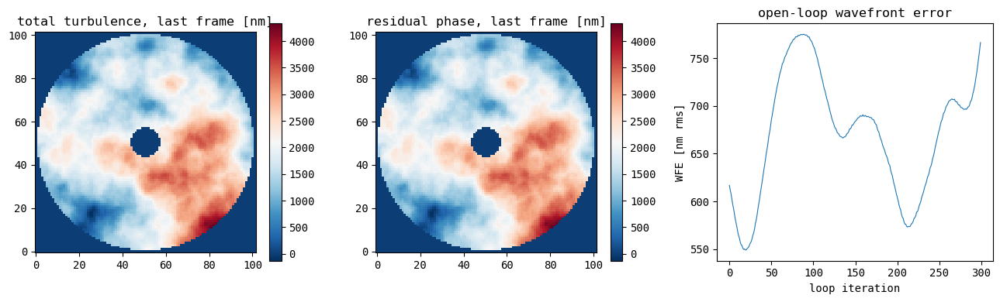

In [8]:
# --- 2.2 Open loop: turbulence, residual phase, WFE time series -----------
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
im = ax[0].imshow(crop_to_pupil(open_sim.scrns.sum(0), open_sim) * open_sim.mask, cmap='RdBu_r')
ax[0].set_title('total turbulence, last frame [nm]'); fig.colorbar(im, ax=ax[0])
im = ax[1].imshow(open_sim.sciPhase[0][-1], cmap='RdBu_r')
ax[1].set_title('residual phase, last frame [nm]'); fig.colorbar(im, ax=ax[1])
ax[2].plot(open_sim.WFE[0], lw=0.8)
ax[2].set_xlabel('loop iteration'); ax[2].set_ylabel('WFE [nm rms]')
ax[2].set_title('open-loop wavefront error')
plt.tight_layout()
print(f'open-loop WFE: mean {open_sim.WFE[0].mean():.0f} nm rms over the pupil '
      f'(should be ~constant: frozen-flow turbulence is stationary)')


subap FOV = 2.5 arcsec over 10 px -> 0.250 arcsec/px
slope rms (x+y combined): 0.117 arcsec


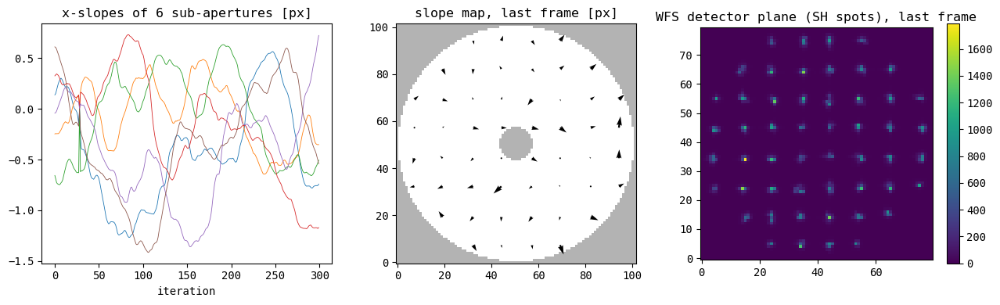

In [9]:
# --- 2.3 Open loop: WFS slopes and spot pattern ---------------------------
wfs = open_sim.wfss[0]
n_sub = wfs.n_subaps
slopes = open_sim.allSlopes                    # (nIters, 2*n_subaps) [subap px]
cx, cy = subap_centres(open_sim, wfs)   # (col, row) centres in the sim-array frame

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].plot(slopes[:, :6], lw=0.6)
ax[0].set_title('x-slopes of 6 sub-apertures [px]'); ax[0].set_xlabel('iteration')
ax[1].imshow(open_sim.mask, cmap='gray', alpha=0.3)
ax[1].quiver(cx, cy, slopes[-1, n_sub:], slopes[-1, :n_sub], angles='xy', scale=30)   # U = slope along col, V = along row
ax[1].set_title('slope map, last frame [px]')
im = ax[2].imshow(wfs.wfsDetectorPlane, cmap='viridis')
ax[2].set_title('WFS detector plane (SH spots), last frame'); fig.colorbar(im, ax=ax[2])
plt.tight_layout()

slope_arcsec = slopes * wfs.pixel_scale        # px -> arcsec
print(f'subap FOV = {wfs.subap_fov} arcsec over {wfs.nx_subap_pixels} px -> {wfs.pixel_scale:.3f} arcsec/px')
print(f'slope rms (x+y combined): {np.sqrt((slope_arcsec**2).mean()):.3f} arcsec')


science lambda = 1.65 um, D = 8.0 m  ->  lambda/D = 43 mas
seeing 0.98*lambda/r0 = 498 mas at 1.65 um  (r0 = 0.67 m at that wavelength)
measured EE50 diameter = 362 mas   |   long-exposure Strehl = 0.032


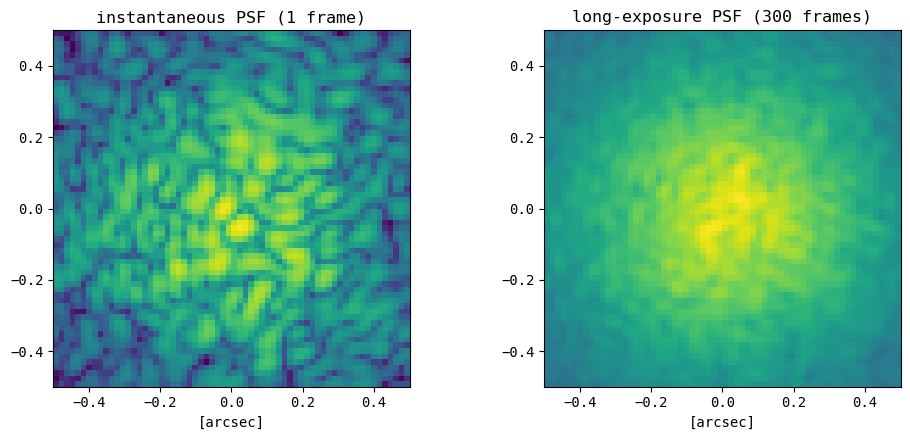

In [10]:
# --- 2.4 Open-loop science PSF: core + halo, EE50 vs seeing -----------------
sci = open_sim.sciCams[0]
pxl = sci.fov / sci.nx_pixels                  # arcsec per science pixel
ext = sci.nx_pixels / 2 * pxl
lam = open_sim.config.scis[0].wavelength
D   = open_sim.config.tel.telDiam
r0_500 = open_sim.config.atmos.r0

psf_inst = open_sim.sciImgsInst[0][-1]
psf_long = open_sim.sciImgs[0]

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a, (im, t) in enumerate([(psf_inst, 'instantaneous PSF (1 frame)'),
                             (psf_long, f'long-exposure PSF ({n_open} frames)')]):
    ax[a].imshow(logim(im / im.max()), extent=[-ext, ext, -ext, ext], vmin=-4, vmax=0)
    ax[a].set_title(t); ax[a].set_xlabel('[arcsec]')
plt.tight_layout()

# seeing expected at the SCIENCE wavelength: r0 scales as lambda^(6/5)
r0_lam = r0_500 * (lam / 500e-9) ** (6/5)
seeing = aotools.r0_to_seeing(r0_lam, lamda=lam)      # arcsec
print(f'science lambda = {lam*1e6:.2f} um, D = {D} m  ->  lambda/D = {lam/D*206265*1000:.0f} mas')
print(f'seeing 0.98*lambda/r0 = {seeing*1000:.0f} mas at {lam*1e6:.2f} um  (r0 = {r0_lam:.2f} m at that wavelength)')
print(f'measured EE50 diameter = {open_sim.ee50d[0]*1000:.0f} mas   |   long-exposure Strehl = {open_sim.longStrehl[0,-1]:.3f}')


### Exercise 2 — open loop
1. Open-loop WFE vs Noll: $\sigma_{OPD} = \sqrt{1.03\,(D/r_0)^{5/3}}\,\lambda/2\pi$ @500 nm (also at 1.65 µm).
2. Off-axis GS (`GSPosition = [20, 0]`): anisoplanatism — WFE increase?
3. Faint GS (`GSMag = 14`, `photonNoise = True`): slopes and PSF?
4. Reproduce `assets/soapytest/SH WFS - Slope variance.ipynb` with `aotools.r0_from_slopes`.


---
# Section 3 — Calibration: pokes → control matrix (~20 min)

`makeIMat()` per DM: **interaction matrix** `D` (`recon.interaction_matrix`, `n_valid_acts × n_meas`) — unit poke per actuator, WFS response with the **atmosphere off**, actuators < 0.1 % of max response dropped — then **control matrix** `R = pinv(D, rcond=svdConditioning)` (truncated SVD cuts noise-amplifying modes). Runtime: `commands = R.T @ slopes` × per-DM `gain`, accumulated.


2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
interaction matrix D: (83, 104)  (valid actuators x WFS measurements)
control matrix    R: (104, 83)  (WFS measurements x valid actuators), R = pinv(D, rcond=0.03)
build time: 0.2 s
DM 0: 2 actuators, 2 valid after calibration
DM 1: 81 actuators, 81 valid after calibration
DM1 (FastPiezo): 81 poke shapes (8, 102, 102) [nm], iMatValue = 500.0 nm


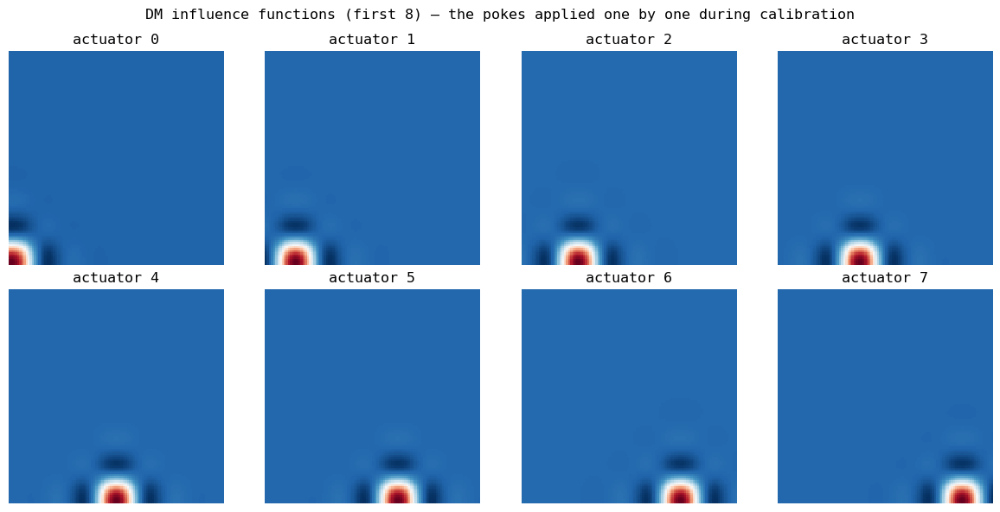

In [11]:
# --- 3.1 Calibration: build the interaction and control matrices -----------
sim.makeIMat(forceNew=True)     # simName=None -> nothing is loaded from disk

imat = sim.recon.interaction_matrix     # (n_valid_acts, n_measurements)
cmat = sim.recon.control_matrix         # (n_measurements, n_valid_acts)
print(f'interaction matrix D: {imat.shape}  (valid actuators x WFS measurements)')
print(f'control matrix    R: {cmat.shape}  (WFS measurements x valid actuators), '
      f'R = pinv(D, rcond={sim.config.recon.svdConditioning})')
print(f'build time: {sim.Timat:.1f} s')
for d, dm in sim.dms.items():
    print(f'DM {d}: {dm.n_acts} actuators, {dm.n_valid_actuators} valid after calibration')

# DM influence functions — the shapes pushed during calibration.
# NOTE: FastPiezo does NOT store iMatShapes (makeIMatShapes is a no-op; it
# interpolates the actuator grid on every frame instead) — so we poke the DM
# directly: dmFrame(e_k) returns the shape produced by actuator k [nm].
dm = sim.dms[1]
n_show = min(8, dm.n_valid_actuators)
shapes = np.zeros((n_show, sim.config.sim.scrnSize, sim.config.sim.scrnSize))
for k in range(n_show):
    cmd = np.zeros(dm.n_valid_actuators); cmd[k] = 1.0
    shapes[k] = dm.dmFrame(cmd)     # poke shape [nm], includes iMatValue
print(f'DM1 ({type(dm).__name__}): {dm.n_valid_actuators} poke shapes {shapes.shape} [nm], '
      f'iMatValue = {dm.dmConfig.iMatValue} nm')

fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for k, a in enumerate(ax.flat):
    a.imshow(crop_to_pupil(shapes[k], sim), cmap='RdBu_r')
    a.set_title(f'actuator {k}'); a.axis('off')
fig.suptitle('DM influence functions (first 8) — the pokes applied one by one during calibration')
plt.tight_layout()


67 of 83 singular values kept at svdConditioning = 0.03
cMat Frobenius norm: 1.354e+01  (larger rcond -> smaller norm, more modes cut)


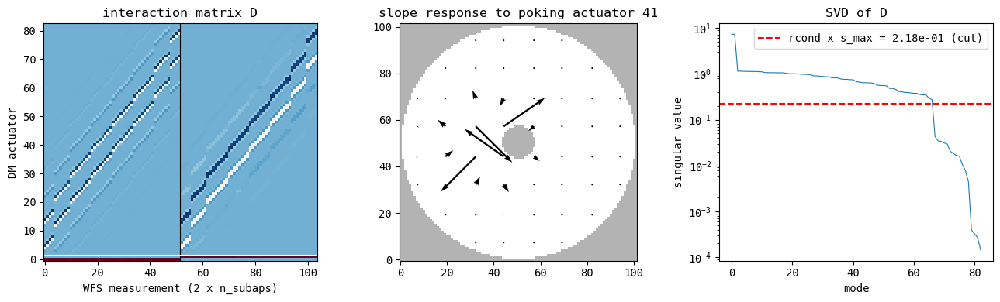

In [12]:
# --- 3.2 Structure of D and the SVD conditioning ---------------------------
wfs = sim.wfss[0]
n_sub = wfs.n_subaps
cx, cy = subap_centres(sim, wfs)   # (col, row) centres in the sim-array frame

s = np.linalg.svd(imat, compute_uv=False)
rcond = sim.config.recon.svdConditioning
n_kept = int((s > rcond * s.max()).sum())

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(imat, aspect='auto', cmap='RdBu_r')
ax[0].axvline(n_sub - 0.5, color='k', lw=0.8)                     # x-slopes | y-slopes
if len(sim.dmAct1) > 1:
    ax[0].axhline(sim.dmAct1[1] - 0.5, color='w', lw=0.8)         # DM 0 (TT) rows | DM 1 rows
ax[0].set_xlabel('WFS measurement (2 x n_subaps)'); ax[0].set_ylabel('DM actuator')
ax[0].set_title('interaction matrix D')

mid = imat.shape[0] // 2
ax[1].imshow(sim.mask, cmap='gray', alpha=0.3)
ax[1].quiver(cx, cy, imat[mid, n_sub:], imat[mid, :n_sub], angles='xy', scale=2)   # U = slope along col, V = along row
ax[1].set_title(f'slope response to poking actuator {mid}')

ax[2].semilogy(s, lw=0.8)
ax[2].axhline(rcond * s.max(), color='r', ls='--',
              label=f'rcond x s_max = {rcond*s.max():.2e} (cut)')
ax[2].set_xlabel('mode'); ax[2].set_ylabel('singular value'); ax[2].legend()
ax[2].set_title('SVD of D')
plt.tight_layout()
print(f'{n_kept} of {len(s)} singular values kept at svdConditioning = {rcond}')
print(f'cMat Frobenius norm: {np.linalg.norm(cmat):.3e}  (larger rcond -> smaller norm, more modes cut)')


### 3.3 Inside the calibration: what one poke looks like

Reproduce a poke by hand — `dm.dmFrame(e_k)` = DM shape [nm], `sim.runWfs(scrns=0, dmShape=<per-DM stack with the poke in plane 1>)` = WFS answer — and view DM shape, WFS image and slope map at once. Each **column of D** is one such slope vector.


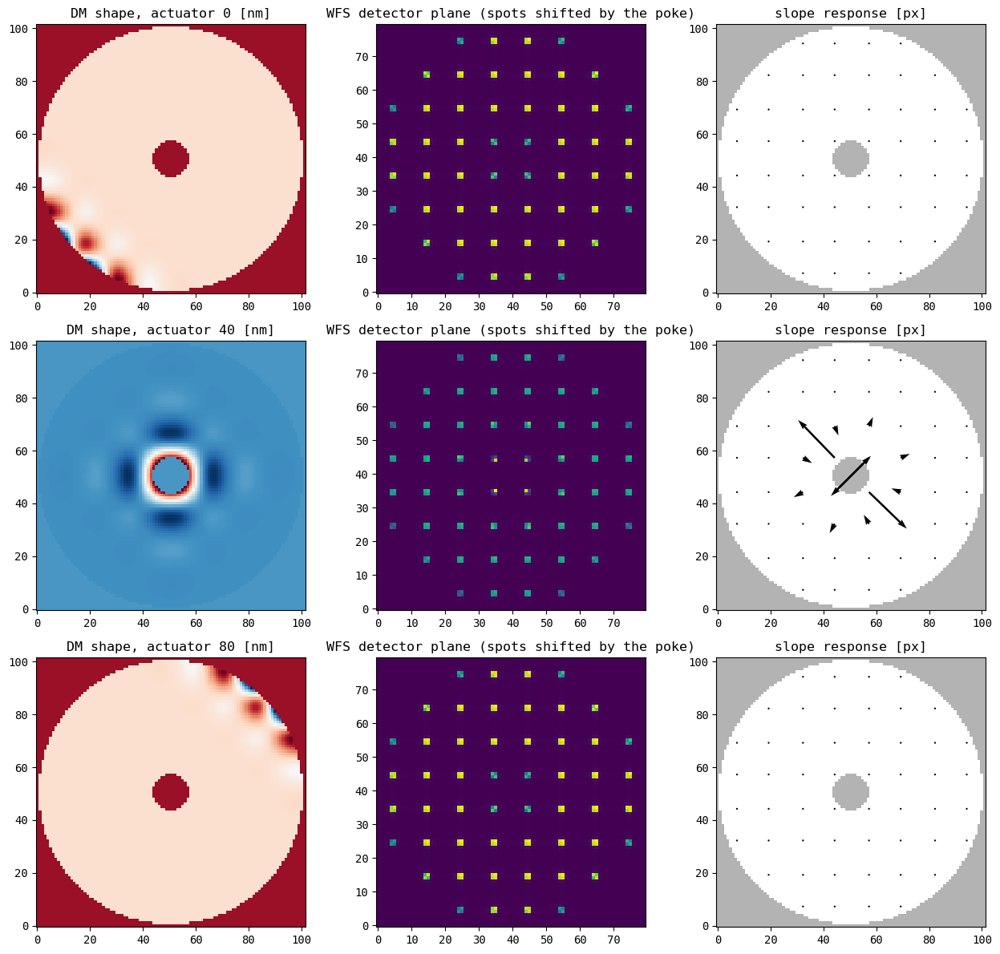

In [15]:
# --- 3.3 One poke, three views: DM shape | WFS image | slope response --------
wfs = sim.wfss[0]
n_sub = wfs.n_subaps
cx, cy = subap_centres(sim, wfs)
dm = sim.dms[1]
zero_scrns = np.zeros_like(sim.scrns)          # atmosphere off, as in makeIMat

pokes = [0, dm.n_valid_actuators // 2, dm.n_valid_actuators - 1]   # first / middle / last actuator
fig, ax = plt.subplots(len(pokes), 3, figsize=(13, 4 * len(pokes)))
for r, k in enumerate(pokes):
    cmd = np.zeros(dm.n_valid_actuators); cmd[k] = 1.0
    shape = dm.dmFrame(cmd)                     # poke shape [nm]
    # runWfs expects dmShape as one plane per DM — the (nDM, scrnSize, scrnSize)
    # stack sim.closed_correction, NOT a single 2D shape (a bare 2D array makes
    # los.performCorrection pass 1D rows to the numba-jitted bilinear_interp -> TypingError)
    dmShape = np.zeros_like(sim.closed_correction); dmShape[1] = shape   # poke on DM 1, TT (DM 0) flat
    slopes = sim.runWfs(scrns=zero_scrns, dmShape=dmShape, loopIter=0)
    img = wfs.wfsDetectorPlane.copy()           # WFS answer to this poke
    ax[r, 0].imshow(crop_to_pupil(shape, sim) * sim.mask, cmap='RdBu_r')
    ax[r, 0].set_title(f'DM shape, actuator {k} [nm]')
    ax[r, 1].imshow(img, cmap='viridis')
    ax[r, 1].set_title('WFS detector plane (spots shifted by the poke)')
    ax[r, 2].imshow(sim.mask, cmap='gray', alpha=0.3)
    ax[r, 2].quiver(cx, cy, slopes[n_sub:], slopes[:n_sub], angles='xy', scale=2)
    ax[r, 2].set_title('slope response [px]')
plt.tight_layout()


In [16]:
# --- 3.4 Video of the calibration: every poke -> WFS spot image --------------
# Re-run the pokes one by one (atmosphere off), recording the WFS detector plane.
from matplotlib import animation
from IPython.display import HTML, display

os.makedirs('videos', exist_ok=True)
dm = sim.dms[1]; wfs = sim.wfss[0]
zero_scrns = np.zeros_like(sim.scrns)
n_pokes = dm.n_valid_actuators

poke_shapes, poke_wfs = [], []
for k in tqdm(range(n_pokes)):
    cmd = np.zeros(n_pokes); cmd[k] = 1.0
    shape = dm.dmFrame(cmd)
    # runWfs expects dmShape as one plane per DM — the (nDM, scrnSize, scrnSize)
    # stack sim.closed_correction, NOT a single 2D shape (a bare 2D array makes
    # los.performCorrection pass 1D rows to the numba-jitted bilinear_interp -> TypingError)
    dmShape = np.zeros_like(sim.closed_correction); dmShape[1] = shape   # poke on DM 1, TT (DM 0) flat
    sim.runWfs(scrns=zero_scrns, dmShape=dmShape, loopIter=0)
    poke_shapes.append(crop_to_pupil(shape, sim) * sim.mask)
    poke_wfs.append(wfs.wfsDetectorPlane.copy())

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
im0 = ax[0].imshow(poke_shapes[0], cmap='RdBu_r'); ax[0].set_title('DM poke shape [nm]')
im1 = ax[1].imshow(poke_wfs[0], cmap='viridis');  ax[1].set_title('WFS detector plane')
fig.suptitle('calibration poke 0')

def update(k):
    im0.set_data(poke_shapes[k]); im1.set_data(poke_wfs[k])
    fig.suptitle(f'calibration: poking actuator {k+1}/{n_pokes} — the spots shift in the WFS')
    return im0, im1

anim = animation.FuncAnimation(fig, update, frames=n_pokes, interval=100, blit=False)
plt.close(fig)
display(HTML(anim.to_jshtml()))     # inline animation (VS Code / Jupyter / Colab)

try:
    anim.save('videos/imat_pokes.mp4', writer='ffmpeg', fps=10, dpi=110)
    print('saved videos/imat_pokes.mp4')
except Exception as e:
    print('mp4 save skipped (is ffmpeg installed?):', e)


100%|██████████| 81/81 [00:00<00:00, 605.84it/s]


saved videos/imat_pokes.mp4


### Exercise 3 — calibration
1. `svdConditioning` 0.03 → 0.3: singular values kept, cMat norm, closed-loop performance?
2. DM 1 `nxActuators` 9 → 17: valid actuators, iMat size, build time, fitting error (§4)?
3. Role of the TT DM (DM 0) and `removeTT` on the WFS?
4. Why calibrate with the atmosphere off? What would `imat_noise = True` add?


---
# Section 4 — Closed loop (~20 min)

Each frame: `commands = R.T @ slopes`; closed DMs accumulate `gain * commands`, delayed by `loopDelay` frames — the main **temporal error** (the atmosphere moves `windSpeed × loopTime` per frame; `tau0 = 0.314 r0 / vBar^(5/3)`). Run `aoloop()` on the calibrated `sim`: Strehl rises to a plateau, residual WFE drops by orders of magnitude.


2 of 300: sh_8x8  Strehl -- sci_0: inst 0.37, long 0.20 

300 of 300: sh_8x8  Strehl -- sci_0: inst 0.52, long 0.57 


Science Camera 0: Long Exposure Strehl Ratio: 0.57
                  EE50 diameter [mas]: 102


Time moving atmosphere: 0.20
Time making IMats and CMats: 0.17
Time in WFS: 0.78
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.06
Time making science image: 0.44


closed-loop long-exposure Strehl (last frame): 0.565
closed-loop WFE (last frame)                : 219 nm rms
closed-loop EE50 diameter                   : 102.4 mas
timings: iMat 0.2s | atmos 0.2s | WFS 0.8s | recon 0.0s | DM 0.1s | sci 0.4s


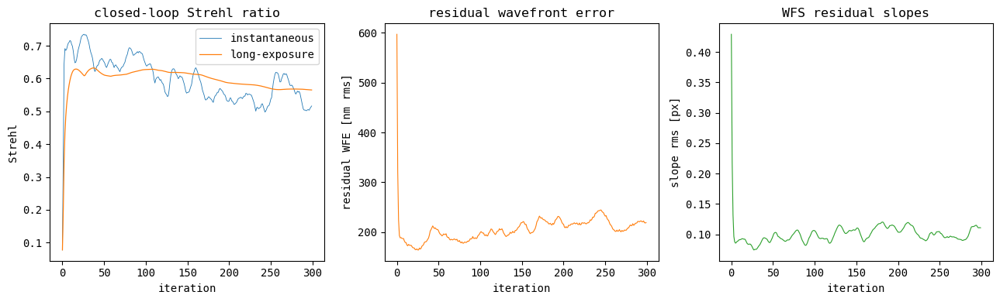

In [17]:
# --- 4.1 Closed-loop run and convergence -----------------------------------
sim.reset_loop()        # zero the buffers, keep the calibration
sim.aoloop()

iters = np.arange(sim.config.sim.nIters)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].plot(iters, sim.instStrehl[0], lw=0.6, label='instantaneous')
ax[0].plot(iters, sim.longStrehl[0], lw=0.9, label='long-exposure')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('Strehl'); ax[0].legend()
ax[0].set_title('closed-loop Strehl ratio')
ax[1].plot(iters, sim.WFE[0], lw=0.8, color='C1')
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('residual WFE [nm rms]')
ax[1].set_title('residual wavefront error')
ax[2].plot(iters, np.sqrt((sim.allSlopes**2).mean(1)), lw=0.8, color='C2')
ax[2].set_xlabel('iteration'); ax[2].set_ylabel('slope rms [px]')
ax[2].set_title('WFS residual slopes')
plt.tight_layout()

print(f'closed-loop long-exposure Strehl (last frame): {sim.longStrehl[0,-1]:.3f}')
print(f'closed-loop WFE (last frame)                : {sim.WFE[0,-1]:.0f} nm rms')
print(f'closed-loop EE50 diameter                   : {sim.ee50d[0]*1000:.1f} mas')
print(f'timings: iMat {sim.Timat:.1f}s | atmos {sim.Tatmos:.1f}s | WFS {sim.Twfs:.1f}s | '
      f'recon {sim.recon.Trecon:.1f}s | DM {sim.Tdm:.1f}s | sci {sim.Tsci:.1f}s')


Strehl : open 0.032  ->  closed 0.565
WFE    : open 766 nm  ->  closed 219 nm rms
EE50   : open 362 mas  ->  closed 102 mas


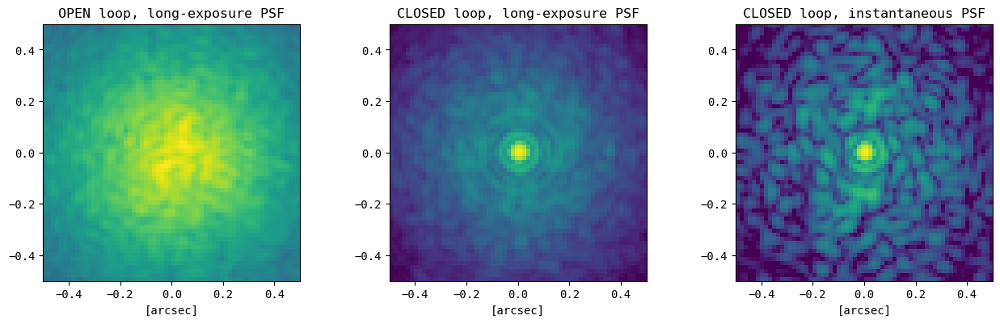

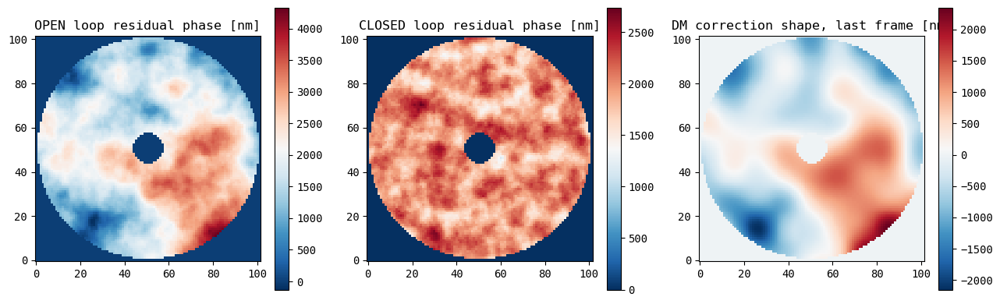

In [18]:
# --- 4.2 Open loop vs closed loop ------------------------------------------
sci = sim.sciCams[0]
pxl = sci.fov / sci.nx_pixels
ext = sci.nx_pixels / 2 * pxl

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, (im, t) in enumerate([(open_sim.sciImgs[0], 'OPEN loop, long-exposure PSF'),
                             (sim.sciImgs[0], 'CLOSED loop, long-exposure PSF'),
                             (sim.sciImgsInst[0][-1], 'CLOSED loop, instantaneous PSF')]):
    ax[a].imshow(logim(im / im.max()), extent=[-ext, ext, -ext, ext], vmin=-4, vmax=0)
    ax[a].set_title(t); ax[a].set_xlabel('[arcsec]')
plt.tight_layout()

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
im = ax[0].imshow(open_sim.sciPhase[0][-1], cmap='RdBu_r'); fig.colorbar(im, ax=ax[0])
ax[0].set_title('OPEN loop residual phase [nm]')
im = ax[1].imshow(sim.sciPhase[0][-1], cmap='RdBu_r'); fig.colorbar(im, ax=ax[1])
ax[1].set_title('CLOSED loop residual phase [nm]')
im = ax[2].imshow(crop_to_pupil(sim.combinedCorrection.sum(0), sim) * sim.mask, cmap='RdBu_r')
fig.colorbar(im, ax=ax[2])
ax[2].set_title('DM correction shape, last frame [nm]')
plt.tight_layout()

print(f'Strehl : open {open_sim.longStrehl[0,-1]:.3f}  ->  closed {sim.longStrehl[0,-1]:.3f}')
print(f'WFE    : open {open_sim.WFE[0,-1]:.0f} nm  ->  closed {sim.WFE[0,-1]:.0f} nm rms')
print(f'EE50   : open {open_sim.ee50d[0]*1000:.0f} mas  ->  closed {sim.ee50d[0]*1000:.0f} mas')


### 4.2b Watch the loop run — video

Per loop frame (closed loop): WFS detector plane, DM shape, instantaneous PSF — inline below, saved to `videos/closed_loop.mp4`.


In [21]:
# --- 4.2b Loop video: WFS spots | DM shape | instantaneous PSF ---------------
from matplotlib import animation
from IPython.display import HTML, display

os.makedirs('videos', exist_ok=True)
sim.reset_loop()                 # zero the buffers, keep the calibration
n_frames = 120
wfs_f, dm_f, psf_f = [], [], []
for i in tqdm(range(n_frames)):
    sim.loopFrame()
    wfs_f.append(sim.wfss[0].wfsDetectorPlane.copy())
    dm_f.append(crop_to_pupil(sim.combinedCorrection.sum(0), sim) * sim.mask)
    psf_f.append(logim(sim.sciCams[0].detector))    # log10 of the instantaneous PSF

psf_max = max(f.max() for f in psf_f)
dm_absmax = max(np.abs(f).max() for f in dm_f)   # fixed symmetric nm scale for the DM panel
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
im0 = ax[0].imshow(wfs_f[0], cmap='viridis');                       ax[0].set_title('WFS detector plane')
# set_data() does NOT re-autoscale the colour norm, and dm_f[0] is all zeros after
# reset_loop() (vmin=vmax=0) -> without explicit vmin/vmax the DM panel stays flat.
im1 = ax[1].imshow(dm_f[0], cmap='RdBu_r', vmin=-dm_absmax, vmax=dm_absmax); ax[1].set_title('DM correction [nm]')
im2 = ax[2].imshow(psf_f[0] - psf_max, vmin=-4, vmax=0);            ax[2].set_title('instantaneous PSF (log10)')
fig.suptitle('frame 0')

def update(i):
    im0.set_data(wfs_f[i]); im1.set_data(dm_f[i]); im2.set_data(psf_f[i] - psf_max)
    fig.suptitle(f'closed loop, frame {i+1}/{n_frames} — inst Strehl {sim.instStrehl[0][i]:.2f}, '
                 f'WFE {sim.WFE[0][i]:.0f} nm')
    return im0, im1, im2

anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=100, blit=False)
plt.close(fig)
display(HTML(anim.to_jshtml()))

try:
    anim.save('videos/closed_loop.mp4', writer='ffmpeg', fps=10, dpi=110)
    print('saved videos/closed_loop.mp4')
except Exception as e:
    print('mp4 save skipped (is ffmpeg installed?):', e)


  0%|          | 0/120 [00:00<?, ?it/s]

18 of 300: sh_8x8  Strehl -- sci_0: inst 0.66, long 0.55 

 15%|█▌        | 18/120 [00:00<00:00, 177.52it/s]

39 of 300: sh_8x8  Strehl -- sci_0: inst 0.54, long 0.58 

 32%|███▎      | 39/120 [00:00<00:00, 195.94it/s]

59 of 300: sh_8x8  Strehl -- sci_0: inst 0.57, long 0.56 

... (4 outputs left out)

 88%|████████▊ | 105/120 [00:00<00:00, 200.61it/s]

120 of 300: sh_8x8  Strehl -- sci_0: inst 0.55, long 0.54 

100%|██████████| 120/120 [00:00<00:00, 194.81it/s]


saved videos/closed_loop.mp4


### 4.3 Parameter study — gain, delay, seeing

- **gain** `dm.gain`: fraction of residual applied per frame — too low sluggish, too high (with delay) unstable;
- **delay** `loopDelay` [frames]: latency → temporal error;
- **seeing** `atmos.r0`: sets $(D/r_0)^{5/3}$ → fitting error.

Swept below with a fresh reproducible sim per point (same `randomSeed` → identical atmosphere; ~30 s per run — lower `nIters` if slow).


  0%|          | 0/5 [00:00<?, ?it/s]

config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.44, long 0.51 


Science Camera 0: Long Exposure Strehl Ratio: 0.51
                  EE50 diameter [mas]: 126


Time moving atmosphere: 0.17
Time making IMats and CMats: 0.18
Time in WFS: 0.42
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.38




 20%|██        | 1/5 [00:01<00:07,  1.77s/it]

config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.49, long 0.56 


Science Camera 0: Long Exposure Strehl Ratio: 0.56
                  EE50 diameter [mas]: 102


Time moving atmosphere: 0.18
Time making IMats and CMats: 0.18
Time in WFS: 0.44
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.06
Time making science image: 0.38




 40%|████      | 2/5 [00:03<00:05,  1.80s/it]

config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.51, long 0.57 


Science Camera 0: Long Exposure Strehl Ratio: 0.57
                  EE50 diameter [mas]: 94


Time moving atmosphere: 0.17
Time making IMats and CMats: 0.22
Time in WFS: 0.42
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.37




... (10 outputs left out)

 75%|███████▌  | 3/4 [00:05<00:01,  1.72s/it]

config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.02, long 0.02 


Science Camera 0: Long Exposure Strehl Ratio: 0.02
                  EE50 diameter [mas]: nan


Time moving atmosphere: 0.17
Time making IMats and CMats: 0.18
Time in WFS: 0.42
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.06
Time making science image: 0.37




100%|██████████| 4/4 [00:06<00:00,  1.72s/it]


 gain | Strehl | WFE [nm]
  0.2 |  0.507 |     265
  0.4 |  0.561 |     249
  0.6 |  0.573 |     245
  0.8 |  0.578 |     242
  1.0 |  0.580 |     241
 delay | Strehl | WFE [nm]
   0   |  0.573 |     245
   1   |  0.562 |     246
   2   |  0.140 |     474
   3   |  0.019 |    3597


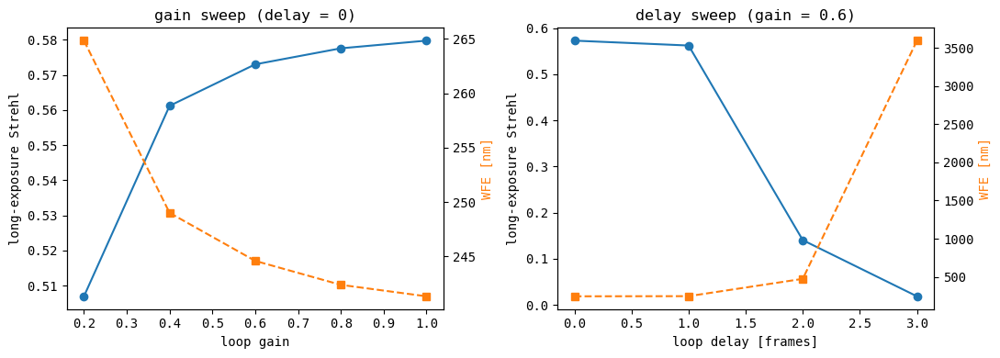

In [20]:
# --- 4.3 Sweep loop gain and loop delay (fresh reproducible sim per point) --
def run_sim(gain=None, loopDelay=None, r0=None, nIters=250):
    # Fresh closed-loop run of sh_8x8.yaml with overrides; returns the sim object.
    s = soapy.Sim(soapy_conf('sh_8x8.yaml'))
    s.config.sim.simName = None
    s.config.sim.logfile = None
    s.config.sim.verbosity = 0
    s.config.sim.nIters = nIters
    s.config.atmos.randomSeed = 0          # same atmosphere for every run
    for f in ['saveSlopes', 'saveInstPsf', 'saveSciRes']:
        setattr(s.config.sim, f, True)
    if gain is not None:
        for dm in s.config.dms:            # loop gain is per-DM (applied in recon.apply_gain)
            dm.gain = gain
    if loopDelay is not None:
        s.config.sim.loopDelay = loopDelay
    if r0 is not None:
        s.config.atmos.r0 = r0
    s.aoinit()
    s.makeIMat(forceNew=True)
    s.aoloop()
    return s

# gain sweep at zero delay
gains = [0.2, 0.4, 0.6, 0.8, 1.0]
strehl_g, wfe_g = [], []
for g in tqdm(gains):
    s = run_sim(gain=g)
    strehl_g.append(s.longStrehl[0, -1])
    wfe_g.append(s.WFE[0, -1])

# delay sweep at gain 0.6
delays = [0, 1, 2, 3]
strehl_d, wfe_d = [], []
for dl in tqdm(delays):
    s = run_sim(gain=0.6, loopDelay=dl)
    strehl_d.append(s.longStrehl[0, -1])
    wfe_d.append(s.WFE[0, -1])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(gains, strehl_g, 'o-', label='Strehl')
ax[0].set_xlabel('loop gain'); ax[0].set_ylabel('long-exposure Strehl'); ax[0].set_title('gain sweep (delay = 0)')
ax0b = ax[0].twinx(); ax0b.plot(gains, wfe_g, 's--', color='C1'); ax0b.set_ylabel('WFE [nm]', color='C1')
ax[1].plot(delays, strehl_d, 'o-', label='Strehl')
ax[1].set_xlabel('loop delay [frames]'); ax[1].set_ylabel('long-exposure Strehl'); ax[1].set_title('delay sweep (gain = 0.6)')
ax1b = ax[1].twinx(); ax1b.plot(delays, wfe_d, 's--', color='C1'); ax1b.set_ylabel('WFE [nm]', color='C1')
plt.tight_layout()

print(' gain | Strehl | WFE [nm]')
for g, st, wf in zip(gains, strehl_g, wfe_g):
    print(f'  {g:.1f} |  {st:.3f} | {wf:7.0f}')
print(' delay | Strehl | WFE [nm]')
for dl, st, wf in zip(delays, strehl_d, wfe_d):
    print(f'   {dl}   |  {st:.3f} | {wf:7.0f}')


### Exercise 4 — closed loop & error budgets
1. Best gain from the sweep? `gain = 1.0`, `loopDelay = 2` — why?
2. `run_sim(r0=0.10 / 0.30)`: residual WFE ∝ $(D/r_0)^{5/6}$ (fitting error)?
3. `nxSubaps = 16` + `nxActuators = 17`: Strehl gain vs cost (iMat size, times)?
4. Off-axis target (`position = [10, 0]`): anisoplanatism vs `aotools.isoplanaticAngle`?
5. `propagationMode = "Physical"` (scintillation); PWFS & modal DMs in Ex. 6–7; more configs in `assets/soapy/conf/`.


### Exercise 5 (optional) — single-mode fiber coupling

A single-mode fiber accepts only its Gaussian mode → injected flux = **coupling efficiency** $\eta = |\sum \mathrm{fibre\_mode} \cdot E_{focal} \cdot \mathrm{mask}|^2$. soapy: `scis[0].type = 'singleModeFibre'` (`instStrehl` = η; `aoinit()` prints the DL reference `refStrehl` ≈ 0.8 — Airy ≠ Gaussian).

1. Open vs closed (below): mean η vs §4 Strehl; η_closed ≈ Strehl × η_ref?
2. Why η < 1 even for a perfect PSF? (mode mismatch; circular-pupil optimum ≈ 0.81)
3. Misalignment (target `[2, 0]` arcsec, static TT): how fast does η drop?


<>:27: SyntaxWarning: invalid escape sequence '\e'
<>:27: SyntaxWarning: invalid escape sequence '\e'
/var/folders/y8/qwkl8q7s08l_x77m0b624hm40000gn/T/ipykernel_83973/1141343614.py:27: SyntaxWarning: invalid escape sequence '\e'
  ax[0].set_xlabel('iteration'); ax[0].set_ylabel('coupling efficiency $\eta$')


config found: conf/sh_8x8.yaml
Coupling efficiency: 0.777
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.02, long 0.00 


Science Camera 0: Long Exposure Strehl Ratio: 0.00
                  EE50 diameter [mas]: 354


Time moving atmosphere: 0.17
Time making IMats and CMats: 0.19
Time in WFS: 0.39
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.35


config found: conf/sh_8x8.yaml
Coupling efficiency: 0.777
2 of 2: Generating 2 Actuator DM iMat
81 of 81: Generating 81 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.34, long 0.00 


Science Camera 0: Long Exposure Strehl Ratio: 0.00
                  EE50 diameter [mas]: 94


Time moving atmosphere: 0.17
Time making IMats and CMats: 0.17
Time in WFS: 0.40
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.05
Time making science image: 0.37


mean eta (after frame 50): 

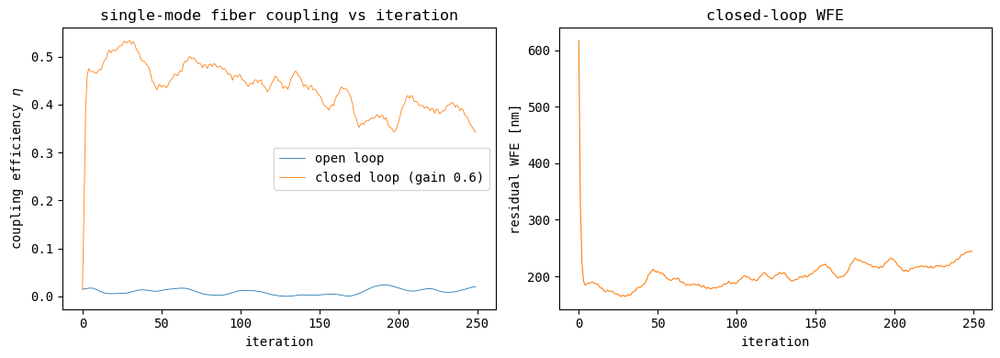

In [22]:
# --- Exercise 5 (optional): single-mode fiber coupling ---------------------
# singleModeFibre science camera: the reported instStrehl is the coupling
# efficiency eta = |<fibre_mode | E_focal>|^2 (Gaussian mode vs Airy PSF).
def run_fibre(gain, nIters=250):
    s = soapy.Sim(soapy_conf('sh_8x8.yaml'))
    s.config.sim.simName = None
    s.config.sim.logfile = None
    s.config.sim.verbosity = 0
    s.config.sim.nIters = nIters
    s.config.atmos.randomSeed = 0
    s.config.scis[0].type = 'singleModeFibre'   # fiber instead of PSF camera
    for dm in s.config.dms:
        dm.gain = gain
    s.aoinit()          # prints the diffraction-limited reference coupling
    s.makeIMat(forceNew=True)
    s.aoloop()
    return s

s_open   = run_fibre(gain=0.0)    # open loop
s_closed = run_fibre(gain=0.6)    # closed loop

eta_open, eta_closed = s_open.instStrehl[0], s_closed.instStrehl[0]
iters = np.arange(s_closed.config.sim.nIters)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(iters, eta_open, lw=0.6, label='open loop')
ax[0].plot(iters, eta_closed, lw=0.6, label='closed loop (gain 0.6)')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('coupling efficiency $\eta$')
ax[0].set_title('single-mode fiber coupling vs iteration'); ax[0].legend()
ax[1].plot(iters, s_closed.WFE[0], lw=0.8, color='C1')
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('residual WFE [nm]')
ax[1].set_title('closed-loop WFE')
plt.tight_layout()
print(f'mean eta (after frame 50): open {eta_open[50:].mean():.3f}  ->  closed {eta_closed[50:].mean():.3f}')
print(f'closed-loop residual WFE : {s_closed.WFE[0,-1]:.0f} nm rms')


### Exercise 6 — Pyramid WFS (`conf/pwfs.yaml`)

A **pyramid WFS** puts a 4-faced pyramid in the focal plane: the detector sees **4 pupil images**, the wavefront in their intensity differences; the beam is **modulated** on a circle (`nb_modulation` positions/frame) to linearise. soapy: `type: Pyramid`; `conf/pwfs.yaml` = standalone system (4 m, 20×20 subaps, PWFS + Zernike DM).

1. `wfs.wfsDetectorPlane` = the 4 pupils; poke one DM mode (as in 3.3): which brighten/darken?
2. Slope rms and closed-loop Strehl/WFE vs the SH system — gain vs cost (frame time ∝ `nb_modulation`)?
3. `nb_modulation = 1`: what happens to the slopes?


config found: conf/pwfs.yaml
WFS: type=Pyramid, nxSubaps=20, nb_modulation=32, amplitude_modulation=0.1 arcsec, pupil_separation=6 px
DM : type=Zernike, nxActuators=45 (Zernike modes)
45 of 45: Generating 45 Actuator DM iMat
60 of 60: pwfs  Strehl -- sci_0: inst 0.89, long 0.81 


Science Camera 0: Long Exposure Strehl Ratio: 0.81
                  EE50 diameter [mas]: 99


Time moving atmosphere: 0.02
Time making IMats and CMats: 1.86
Time in WFS: 2.36
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.18
Time making science image: 2.14


PWFS closed loop : long Strehl 0.813, WFE 176 nm rms, WFS time/frame 39 ms
SH reference (Sec 4): long Strehl 0.000, WFE 219 nm


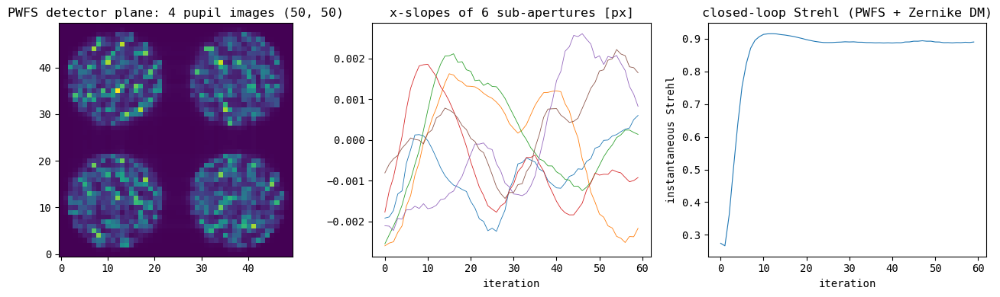

In [23]:
# --- Exercise 6: Pyramid WFS, standalone conf/pwfs.yaml ----------------------
psim = soapy.Sim(soapy_conf('pwfs.yaml'))
psim.config.sim.simName = None
psim.config.sim.logfile = None
psim.config.sim.verbosity = 0
psim.config.sim.nIters = 60
psim.config.atmos.randomSeed = 0
for f in ['saveSlopes', 'saveInstPsf', 'saveSciRes']:
    setattr(psim.config.sim, f, True)
psim.config.dms[0].nxActuators = 45     # fewer Zernike modes -> faster calibration

pw = psim.config.wfss[0]
print(f'WFS: type={pw.type}, nxSubaps={pw.nxSubaps}, nb_modulation={pw.nb_modulation}, '
      f'amplitude_modulation={pw.amplitude_modulation} arcsec, pupil_separation={pw.pupil_separation} px')
print(f'DM : type={psim.config.dms[0].type}, nxActuators={psim.config.dms[0].nxActuators} (Zernike modes)')

psim.aoinit()
psim.makeIMat(forceNew=True)
psim.aoloop()

wfs = psim.wfss[0]
iters = np.arange(psim.config.sim.nIters)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(wfs.wfsDetectorPlane, cmap='viridis')
ax[0].set_title(f'PWFS detector plane: 4 pupil images {wfs.wfsDetectorPlane.shape}')
ax[1].plot(iters, psim.allSlopes[:, :6], lw=0.6)
ax[1].set_title('x-slopes of 6 sub-apertures [px]'); ax[1].set_xlabel('iteration')
ax[2].plot(iters, psim.instStrehl[0], lw=0.8)
ax[2].set_xlabel('iteration'); ax[2].set_ylabel('instantaneous Strehl')
ax[2].set_title('closed-loop Strehl (PWFS + Zernike DM)')
plt.tight_layout()
print(f'PWFS closed loop : long Strehl {psim.longStrehl[0,-1]:.3f}, WFE {psim.WFE[0,-1]:.0f} nm rms, '
      f'WFS time/frame {psim.Twfs/psim.config.sim.nIters*1000:.0f} ms')
print(f'SH reference (Sec 4): long Strehl {sim.longStrehl[0,-1]:.3f}, WFE {sim.WFE[0,-1]:.0f} nm')


### Exercise 7 — modal DM: Zernike (worked) vs Karhunen–Loève (optional)

A **modal DM** is driven by orthogonal modes, not per-actuator pokes: `type: Zernike` or `KarhunenLoeve`, `nxActuators` = number of modes; influence functions in `dm.iMatShapes` (calibration unchanged).

1. Which modes are dropped by calibration (`n_valid_actuators` vs `nxActuators`), why?
2. Closed-loop Strehl/WFE vs the 9×9 FastPiezo of §4 at same `nIters`?
3. Optional: `run_modal('KarhunenLoeve')` — KL vs Zernike at the same mode count?


config found: conf/sh_8x8.yaml
2 of 2: Generating 2 Actuator DM iMat
45 of 45: Generating 45 Actuator DM iMat
250 of 250: sh_8x8  Strehl -- sci_0: inst 0.38, long 0.41 


Science Camera 0: Long Exposure Strehl Ratio: 0.41
                  EE50 diameter [mas]: 236


Time moving atmosphere: 0.16
Time making IMats and CMats: 0.10
Time in WFS: 0.41
	 of which time spent in : 0.00
Time in Reconstruction: 0.00
Time in DM: 0.10
Time making science image: 0.35


DM1: Zernike, 45 modes, 45 valid after calibration
modal DM (Zernike, 45 modes): long Strehl 0.412, WFE 273 nm rms
reference FastPiezo 9x9 (Sec 4): long Strehl 0.000, WFE 219 nm


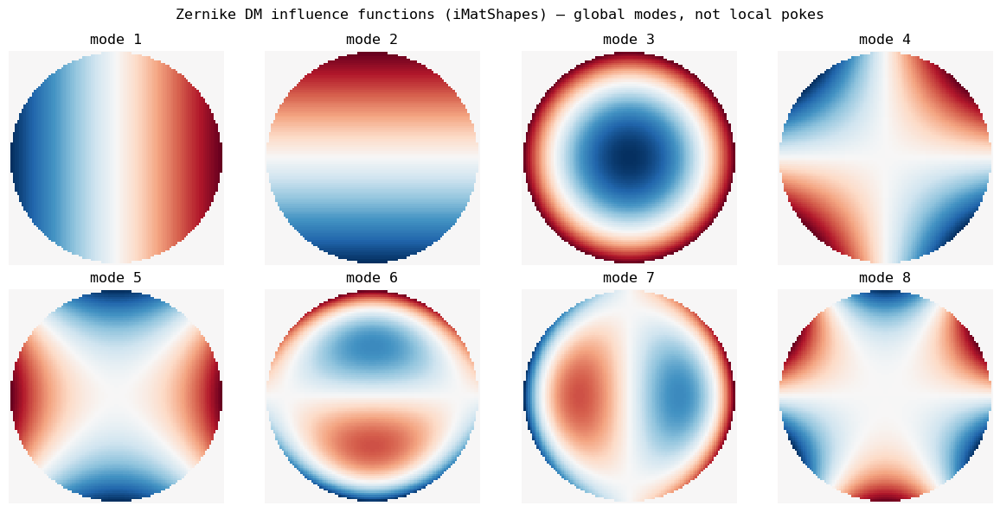

In [24]:
# --- Exercise 7: modal DM (Zernike worked, KarhunenLoeve optional) -----------
def run_modal(dm_type, n_modes=45, nIters=250):
    s = soapy.Sim(soapy_conf('sh_8x8.yaml'))
    s.config.sim.simName = None
    s.config.sim.logfile = None
    s.config.sim.verbosity = 0
    s.config.sim.nIters = nIters
    s.config.atmos.randomSeed = 0
    for f in ['saveSlopes', 'saveInstPsf', 'saveSciRes']:
        setattr(s.config.sim, f, True)
    s.config.dms[1].type = dm_type          # modal DM instead of FastPiezo
    s.config.dms[1].nxActuators = n_modes   # = number of modes
    s.aoinit()
    s.makeIMat(forceNew=True)
    s.aoloop()
    return s

s_mod = run_modal('Zernike', n_modes=45)

# modal DMs store their influence functions (unlike FastPiezo): show the first 8
dm = s_mod.dms[1]
print(f'DM1: {type(dm).__name__}, {dm.n_acts} modes, {dm.n_valid_actuators} valid after calibration')
shapes = dm.iMatShapes[:8]                  # (8, scrnSize, scrnSize)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for k, a in enumerate(ax.flat):
    a.imshow(crop_to_pupil(shapes[k], s_mod), cmap='RdBu_r')
    a.set_title(f'mode {k+1}'); a.axis('off')
fig.suptitle('Zernike DM influence functions (iMatShapes) — global modes, not local pokes')
plt.tight_layout()

print(f'modal DM (Zernike, 45 modes): long Strehl {s_mod.longStrehl[0,-1]:.3f}, WFE {s_mod.WFE[0,-1]:.0f} nm rms')
print(f'reference FastPiezo 9x9 (Sec 4): long Strehl {sim.longStrehl[0,-1]:.3f}, WFE {sim.WFE[0,-1]:.0f} nm')

# optional: s_kl = run_modal('KarhunenLoeve', n_modes=45)   # then compare the same way


### Exercise 7b — video of the modal calibration

Same idea as §3.4, but for the modal DM of Exercise 7: each frame pokes one **Zernike mode** (atmosphere off, as in `makeIMat`) and shows the mode shape next to the WFS detector plane. Inline below, saved to `videos/modal_imat.mp4`.


In [25]:
# --- Exercise 7b: record the modal iMat — one Zernike mode per frame ---------
from matplotlib import animation
from IPython.display import HTML, display

os.makedirs('videos', exist_ok=True)
dm = s_mod.dms[1]
wfs = s_mod.wfss[0]
zero_scrns = np.zeros_like(s_mod.scrns)          # atmosphere off, as in makeIMat
n_modes = dm.n_valid_actuators

mode_shapes, mode_wfs = [], []
for k in tqdm(range(n_modes)):
    cmd = np.zeros(n_modes); cmd[k] = 1.0
    shape = dm.dmFrame(cmd)                       # mode shape [nm]
    dmShape = np.zeros_like(s_mod.closed_correction); dmShape[1] = shape   # per-DM stack, as in 3.3
    s_mod.runWfs(scrns=zero_scrns, dmShape=dmShape, loopIter=0)
    mode_shapes.append(crop_to_pupil(shape, s_mod) * s_mod.mask)
    mode_wfs.append(wfs.wfsDetectorPlane.copy())

# fixed colour scale: mode 1 (piston) is ~0 after dmFrame's mean removal, so an
# autoscaled norm on frame 0 would be degenerate and set_data never re-autoscales
shape_absmax = max(np.abs(m).max() for m in mode_shapes)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
im0 = ax[0].imshow(mode_shapes[0], cmap='RdBu_r', vmin=-shape_absmax, vmax=shape_absmax)
ax[0].set_title('Zernike mode shape [nm]')
im1 = ax[1].imshow(mode_wfs[0], cmap='viridis');  ax[1].set_title('WFS detector plane')
fig.suptitle('modal calibration, mode 1')

def update(k):
    im0.set_data(mode_shapes[k]); im1.set_data(mode_wfs[k])
    fig.suptitle(f'modal iMat: poking mode {k+1}/{n_modes} — the WFS spots respond')
    return im0, im1

anim = animation.FuncAnimation(fig, update, frames=n_modes, interval=150, blit=False)
plt.close(fig)
display(HTML(anim.to_jshtml()))     # inline animation (VS Code / Jupyter / Colab)

try:
    anim.save('videos/modal_imat.mp4', writer='ffmpeg', fps=7, dpi=110)
    print('saved videos/modal_imat.mp4')
except Exception as e:
    print('mp4 save skipped (is ffmpeg installed?):', e)


100%|██████████| 45/45 [00:00<00:00, 363.37it/s]


saved videos/modal_imat.mp4


---
# Section 5 — Summary & pointers (~15 min)

### What we covered

| Step | Key idea |
|---|---|
| Principle | one YAML → one `Sim`; `aoinit()` builds it, `aoloop()` = `loopFrame()` × `nIters`; data on `sim` (`allSlopes`, `sciImgs`, `longStrehl`, `WFE`, `ee50d`, `recon.interaction_matrix`) |
| Open loop | WFS sees full turbulence; camera sees seeing-limited core+halo (EE50 ≈ $0.98\lambda/r_0$) |
| Calibration | pokes, atmosphere off → `D`; `R = pinv(D, rcond)`; visuals §3.3–3.4 (`videos/imat_pokes.mp4`) |
| Closed loop | `commands += gain·R.T @ slopes`, delayed `loopDelay`; Strehl plateaus, WFE drops (`videos/closed_loop.mp4`) |
| Error budgets | fitting $\propto (D/r_0)^{5/3}$, aliasing, temporal (gain×delay vs $\tau_0$), anisoplanatism, noise |
| Ex. 5–7 | SMF fiber η, pyramid WFS (`conf/pwfs.yaml`), modal DMs (`Zernike`/`KarhunenLoeve`, `iMatShapes`, video `videos/modal_imat.mp4`) |

### Where to go next
- `conf/` lab configs; more systems + tests in `assets/soapy/`; component notebooks in `assets/soapytest/`.
- Pointers only: LGS (`assets/soapy/conf/sh_8x8_lgs*.yaml`), MCAO (`sh_8x8_mcao.yaml`), OOPAO (`assets/ORP_AO_School_How_To.ipynb`). Docs: soapy/aotools readthedocs.

### References
- Fried (1966) $r_0$; Noll (1976); Roddier (1981) $\tau_0$; Assemat & Wilson (2006), Fried (2008); Hardy (1998); Roddier (ed.) (1999). soapy: github.com/AOtools/soapy; aotools: github.com/aotools/aotools.
